## Hydrodynamic model of the Southern North Sea

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch

# dataset helper
from helper import get_altimetry_obs, get_u_v_point_obs, get_wl_point_obs
from helper import plot_shred_reconstruction

import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))

from src.datamanager import DataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate
from src.mSHRED.mSRED import mSHRED

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


## Load Data and Measurement

In [3]:
# folders
dfs_fldr = "datasets/output/Area.dfsu"
msh_fldr = "datasets/input/Mesh_8000_elems_HD_v2.mesh"
obs_fldr  = "datasets/observations/"

msh = mikeio.open(msh_fldr)
dfs = mikeio.open(dfs_fldr)

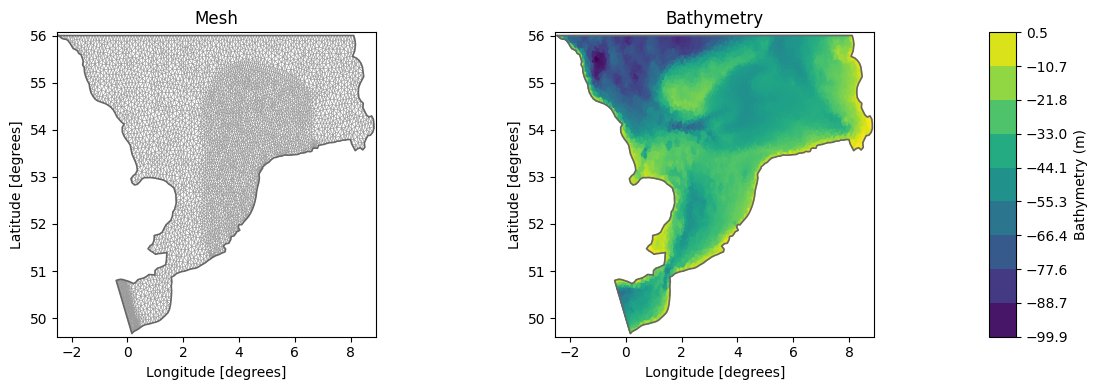

In [4]:
# plot geometry
geom = dfs.geometry

fig, axs = plt.subplots(1,2, figsize = (12,4))
geom.plot.mesh(ax=axs[0])
geom.plot(ax=axs[1])
plt.tight_layout()
plt.show()

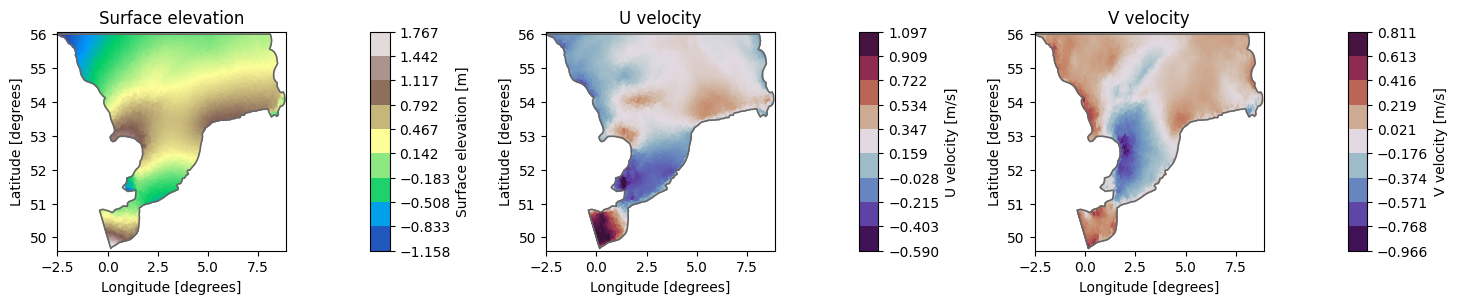

In [5]:
# plot a simulation
ds = dfs.read()

dsH = ds["Surface elevation"]
dsU = ds["U velocity"]
dsV = ds["V velocity"]

plot_time = ds.time[-1]
fig,axs = plt.subplots(1, 3, figsize=(15,5))
dsH.sel(time=plot_time).plot(ax=axs[0], title="Surface elevation", cmap = "terrain")
dsU.sel(time=plot_time).plot(ax=axs[1], title="U velocity", cmap = "twilight_shifted")
dsV.sel(time=plot_time).plot(ax=axs[2], title="V velocity", cmap = "twilight_shifted")
plt.tight_layout()
plt.show()


<Axes: >

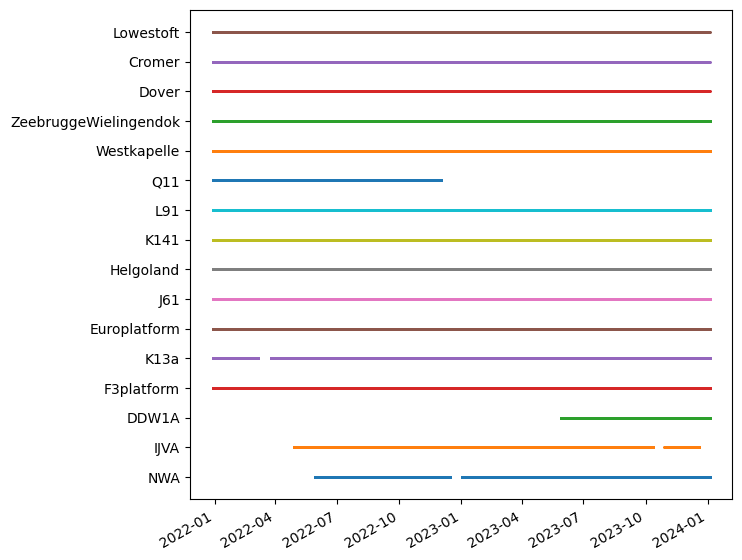

In [6]:
# sensor coverage

wllist = get_wl_point_obs()
ms.plotting.temporal_coverage(wllist)

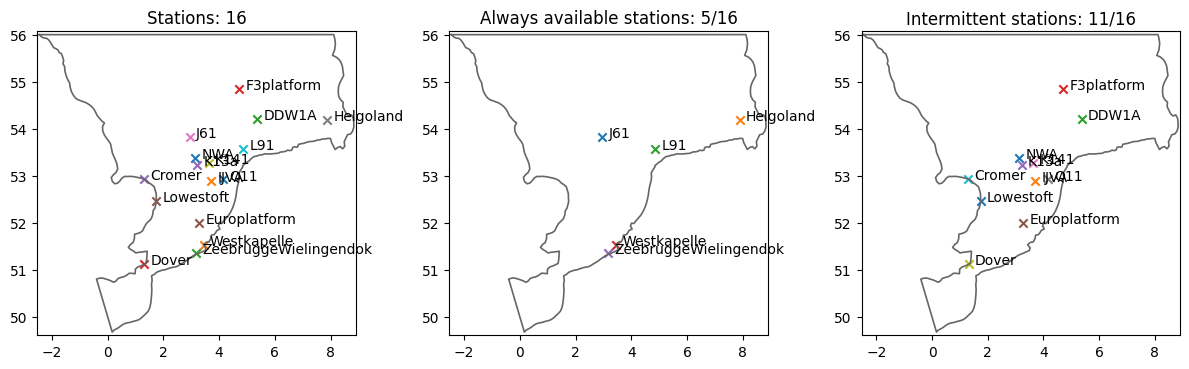

In [7]:
# Select stations with full temporal coverage

stations = []
availables = []
intermittent = []
for i in range(len(wllist)):
    stations.append(wllist[i])
    if ds.time.isin(wllist[i].time).all():
        availables.append(wllist[i])
    else:
        intermittent.append(wllist[i])

fig, axs = plt.subplots(1,3, figsize = (12,4))
ms.plotting.spatial_overview(stations, mod = msh.geometry, figsize = (5,5), ax=axs[0], title=f"Stations: {len(stations)}")
ms.plotting.spatial_overview(availables, mod = msh.geometry, figsize = (5,5), ax=axs[1], title=f"Always available stations: {len(availables)}/{len(stations)}")
ms.plotting.spatial_overview(intermittent, mod = msh.geometry, figsize = (5,5), ax=axs[2], title=f"Intermittent stations: {len(intermittent)}/{len(stations)}")

plt.tight_layout()
plt.show()


In [8]:
# Extract water level measurements

measurements = np.full((ds.time.shape[0], len(stations)), np.nan)

for i in range(len(stations)):
    
    stn_data = pd.read_csv(obs_fldr + stations[i].name + "_wl.csv", index_col = 0)
    measurements[:,i] = stn_data["water_level_filtered"].reindex(ds.time.strftime("%Y-%m-%d %H:%M:%S")).values 

# free memory
del stn_data

In [9]:
# Extract the values and convert to torch tensors

# remove nans from H, U, V 
dsH = dsH.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]
dsU = dsU.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]
dsV = dsV.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]

# outputs
H = torch.tensor(dsH, dtype=torch.float32)
U = torch.tensor(dsU, dtype=torch.float32)
V = torch.tensor(dsV, dtype=torch.float32)

# inputs
measurements = torch.tensor(measurements, dtype=torch.float32)

# print the shape of the arrays
print("H shape:", H.shape)
print("U shape:", U.shape)
print("V shape:", V.shape)
print("Measurements shape:", measurements.shape)

# free memory
del dsH, dsU, dsV

H shape: torch.Size([35039, 8532])
U shape: torch.Size([35039, 8532])
V shape: torch.Size([35039, 8532])
Measurements shape: torch.Size([35039, 16])


In [10]:
ERRORS = []

## Height field


In [11]:

# Data manager

lags = 48
manager = DataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(
    H, id = "Surface elevation" , compress = 12, 
    measurements = measurements, imputer="median"
)
manager.add_data(U, id = "U velocity", compress = 40)
manager.add_data(V, id = "V velocity", compress = 68)

# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(
    verbose = True, unused_data=["U velocity", "V velocity"]
)

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Nuber of nan values in measurements after imputation: 0 



Residual energy of Surface elevation after keeping 12 modes: 0.1678 %
Residual energy of U velocity after keeping 40 modes: 0.1947 %
Residual energy of V velocity after keeping 68 modes: 0.1872 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']
Dataset NOT used: ['U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([28031, 48, 16]) -> torch.Size([28031, 12])
Val:	 torch.Size([3504, 48, 16]) -> torch.Size([3504, 12])
Test:	 torch.Size([3504, 48, 16]) -> torch.Size([3504, 12])

Input shape for the model: 16
Output shape for the model: 12


Starting training...


Training:  76%|███████▋  | 153/200 [41:19<12:41, 16.20s/it, Train Loss=0.0019, Val Loss=0.0022, Patience=39, Best Val Loss=0.0021, LR=1.25e-04]

Early stopping at epoch 154
Training completed with best validation loss: 0.0021


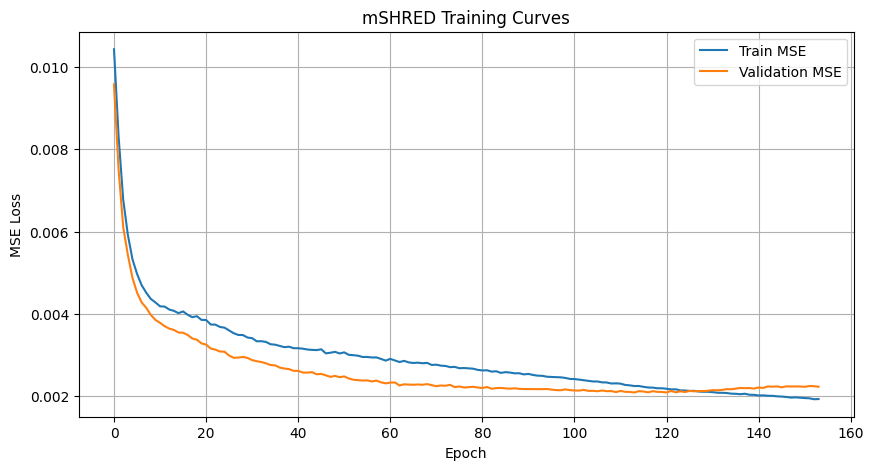

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,1field: Surface elevation,0.001928,0.002235,0.006062,0.092607,0.093887,0.143527


In [12]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=40,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
val_mse, val_mre = evaluate(mshred, val_dataset)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): TR + CNN",
    "type" : "1field: Surface elevation",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_Height.png


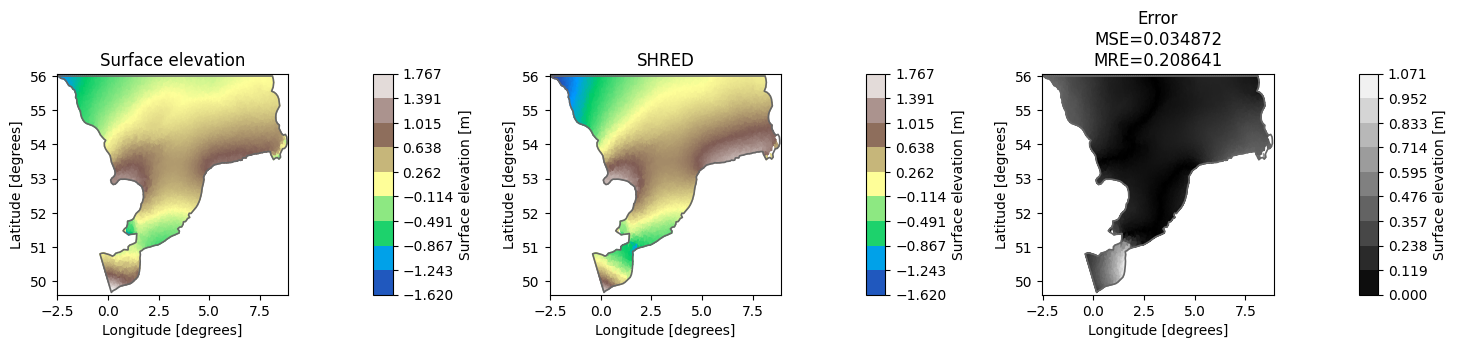

In [13]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="Height", items = "Surface elevation")

del engine, test_reconstruction, ds_shred, ds_error, mshred, manager

## U velocity field

In [14]:

# Data manager

lags = 48
manager = DataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(
    H, id = "Surface elevation" , compress = 12, 
    measurements = measurements, imputer="median"
)
manager.add_data(U, id = "U velocity", compress = 40)
manager.add_data(V, id = "V velocity", compress = 68)

# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(
    verbose = True, unused_data=["Surface elevation", "V velocity"]
)

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Nuber of nan values in measurements after imputation: 0 

Residual energy of Surface elevation after keeping 12 modes: 0.1678 %
Residual energy of U velocity after keeping 40 modes: 0.1947 %
Residual energy of V velocity after keeping 68 modes: 0.1872 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']
Dataset NOT used: ['Surface elevation', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([28031, 48, 16]) -> torch.Size([28031, 40])
Val:	 torch.Size([3504, 48, 16]) -> torch.Size([3504, 40])
Test:	 torch.Size([3504, 48, 16]) -> torch.Size([3504, 40])

Input shape for the model: 16
Output shape for the model: 40


Starting training...


Training: 100%|██████████| 200/200 [47:44<00:00, 14.32s/it, Train Loss=0.0040, Val Loss=0.0049, Patience=0, Best Val Loss=0.0049, LR=0.00e+00] 

Training completed with best validation loss: 0.0049


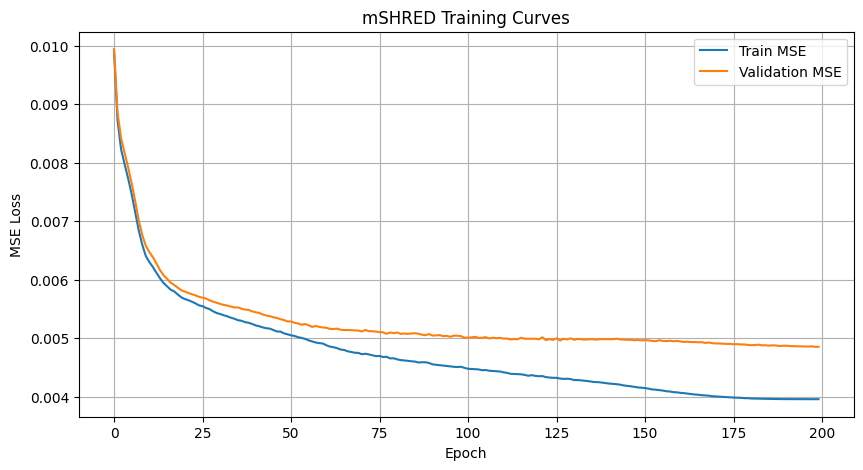

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,1field: Surface elevation,0.001928,0.002235,0.006062,0.092607,0.093887,0.143527
1,(mSHRED): TR + CNN,1field: U velocity,0.003963,0.004861,0.012136,0.125535,0.133367,0.211432


In [15]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=40,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
val_mse, val_mre = evaluate(mshred, val_dataset)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): TR + CNN",
    "type" : "1field: U velocity",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_U velocity.png


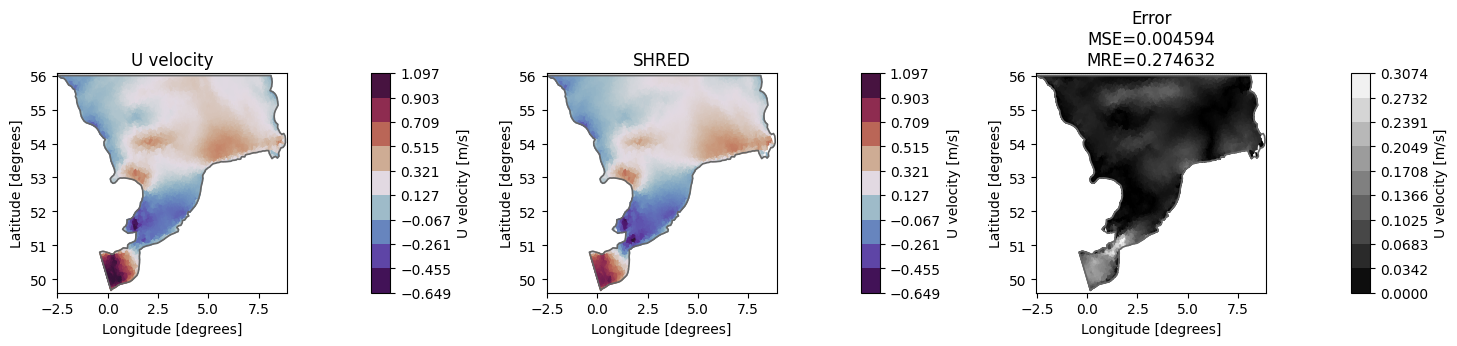

In [16]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="U velocity", items = "U velocity")

del engine, test_reconstruction, ds_shred, ds_error, mshred, manager

## V velocity field

In [17]:

# Data manager

lags = 48
manager = DataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(
    H, id = "Surface elevation" , compress = 12, 
    measurements = measurements, imputer="median"
)
manager.add_data(U, id = "U velocity", compress = 40)
manager.add_data(V, id = "V velocity", compress = 68)

# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(
    verbose = True, unused_data=["Surface elevation", "U velocity"]
)

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Nuber of nan values in measurements after imputation: 0 

Residual energy of Surface elevation after keeping 12 modes: 0.1678 %
Residual energy of U velocity after keeping 40 modes: 0.1947 %
Residual energy of V velocity after keeping 68 modes: 0.1872 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']
Dataset NOT used: ['Surface elevation', 'U velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([28031, 48, 16]) -> torch.Size([28031, 68])
Val:	 torch.Size([3504, 48, 16]) -> torch.Size([3504, 68])
Test:	 torch.Size([3504, 48, 16]) -> torch.Size([3504, 68])

Input shape for the model: 16
Output shape for the model: 68


Starting training...


Training: 100%|██████████| 200/200 [44:27<00:00, 13.34s/it, Train Loss=0.0039, Val Loss=0.0038, Patience=4, Best Val Loss=0.0038, LR=0.00e+00]

Training completed with best validation loss: 0.0038


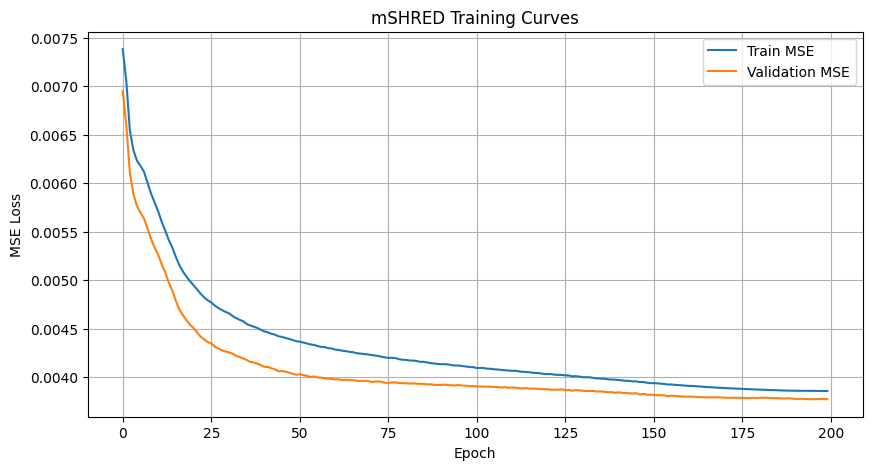

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,1field: Surface elevation,0.001928,0.002235,0.006062,0.092607,0.093887,0.143527
1,(mSHRED): TR + CNN,1field: U velocity,0.003963,0.004861,0.012136,0.125535,0.133367,0.211432
2,(mSHRED): TR + CNN,1field: V velocity,0.003858,0.003772,0.009047,0.123959,0.121872,0.190373


In [18]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=40,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
val_mse, val_mre = evaluate(mshred, val_dataset)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): TR + CNN",
    "type" : "1field: V velocity",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_V velocity.png


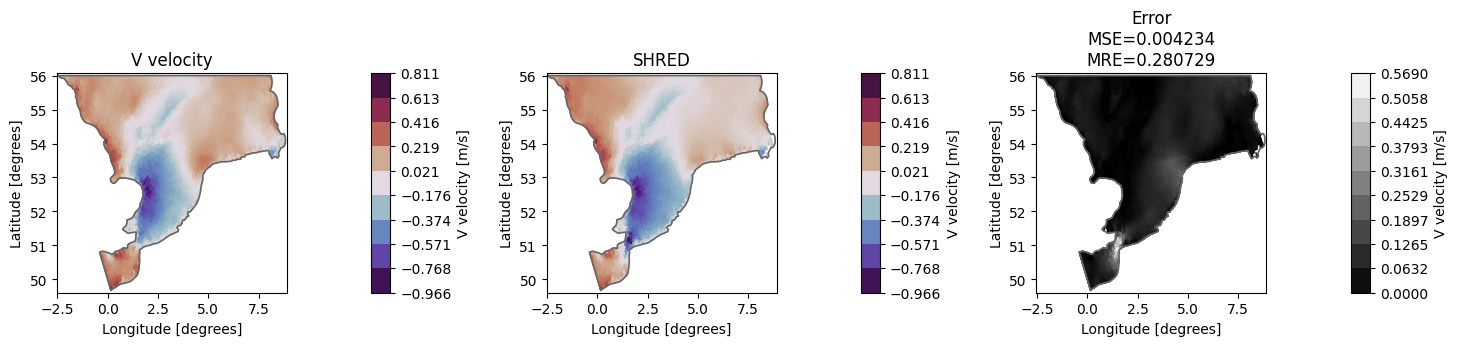

In [19]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="V velocity", items = "V velocity")

del engine, test_reconstruction, ds_shred, ds_error, mshred, manager

## Results